# Parte 3 – Dominio espacial vs. dominio frecuencial

En la Parte 2 vimos que el *speckle* de BUSI es un ruido granular que depende del brillo, y que el ecógrafo ya comprimió y suavizó la imagen. Antes de construir mapas de textura (Parte 4) y segmentar (Parte 5) hay que decidir **si conviene filtrar la imagen y con qué filtro**.

Hay dos formas de filtrar, vistas en la clase de Mejoramiento:
- en el **dominio espacial**, cambiando cada píxel según sus vecinos (media, gaussiano, mediana);
- en el **dominio frecuencial**, pasando la imagen a frecuencias con la transformada de Fourier, atenuando algunas y volviendo (pasabajos ideal, Butterworth y gaussiano).

**La pregunta no es solo cuánto ruido saca cada filtro**, sino **qué le hace a la textura**: el *speckle* es ruido, pero también es la textura del tejido, y la diferencia de textura entre la lesión y el tejido que la rodea es justo lo que vamos a usar en las Partes 4 a 6. Un filtro que saca mucho ruido pero borra el borde de la lesión o iguala su textura con la del tejido nos perjudica.

**Contenido**
1. La imagen en el dominio de la frecuencia: magnitud y fase
2. Los seis filtros y cómo los emparejamos
3. Cómo se ve cada filtro: imagen, perfil del borde, lo que saca (pasa-altos) y bordes de Canny
4. Medición en las 647 imágenes con lesión
5. Resultados: suavizado, bordes, espectro, textura y PSNR/SSIM
6. Conclusiones y filtro elegido para la Parte 4

### Preparación

Igual que en las partes anteriores: le decimos a Python dónde está nuestro código (`src/`) y activamos `autoreload`.

In [1]:
import sys
from pathlib import Path
sys.path.insert(0, str(Path.cwd().parent / 'src'))

%load_ext autoreload
%autoreload 2

Trabajamos siempre sobre las imágenes **sin marcas del ecógrafo**: `cargar_limpio()` aplica `artefactos.limpiar()` de la Parte 1 y devuelve también la máscara de las marcas reconstruidas, para no usar esos píxeles en ninguna medición (el relleno del *inpainting* es más liso que el tejido real).

Como concluyó la Parte 2, **no aplicamos logaritmo antes de filtrar**: la imagen ya viene comprimida por el ecógrafo y un segundo log sobrecorrige el ruido.

In [2]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from scipy.stats import mannwhitneyu, wilcoxon
from skimage import feature

from busi.datos import listar_casos, cargar_caso
from busi.config import load_config
from busi import artefactos, dominios, ruido

cfg = load_config()
SEED = cfg["SEED"]

def cargar_limpio(caso):
    # Imagen sin marcas del ecógrafo (Parte 1), máscara de la lesión y máscara de las marcas reconstruidas.
    img, mascara = cargar_caso(caso)
    img, marcas = artefactos.limpiar(img)
    return img, mascara, marcas

casos = listar_casos().set_index("id")
con_lesion = casos[casos["clase"] != "normal"]
print(f"{len(con_lesion)} imágenes con lesión: {(con_lesion['clase'] == 'benign').sum()} benignas, "
      f"{(con_lesion['clase'] == 'malignant').sum()} malignas")

# nombres para tablas y gráficos
NOMBRES = {"media": "Media", "gaussiano": "Gaussiano (esp.)", "mediana": "Mediana",
           "ideal": "Ideal", "butterworth": "Butterworth", "gaussiano_frec": "Gaussiano (frec.)"}
COLORES = {"media": "tab:blue", "gaussiano": "tab:green", "mediana": "tab:purple",
           "ideal": "tab:red", "butterworth": "tab:orange", "gaussiano_frec": "tab:olive"}

647 imágenes con lesión: 437 benignas, 210 malignas


## 1. La imagen en el dominio de la frecuencia

La **transformada de Fourier 2D** escribe la imagen como una suma de "ondas" (patrones de franjas claras y oscuras) de distintas frecuencias y orientaciones. Cada punto $(u, v)$ del espectro corresponde a una onda:
- su **distancia al centro** es la frecuencia: cerca del centro están las variaciones **lentas** (zonas grandes, la forma general de la lesión); lejos, las **rápidas** (bordes finos, el grano del *speckle*);
- su **dirección** es la orientación de las franjas.

Medimos la frecuencia en **ciclos por píxel**: va de 0 (el centro, el brillo medio) a 0,5 (lo más rápido posible: un píxel claro, uno oscuro). Usamos esta unidad, y no "píxeles del espectro", porque las imágenes de BUSI tienen tamaños distintos y así un mismo valor significa lo mismo en todas.

Cada punto del espectro es un número complejo con:
- **magnitud**: cuánto pesa esa onda en la imagen;
- **fase**: dónde están ubicadas sus crestas.

Como la magnitud del centro es muchísimo más grande que la del resto, se grafica $\log(1 + |F|)$.

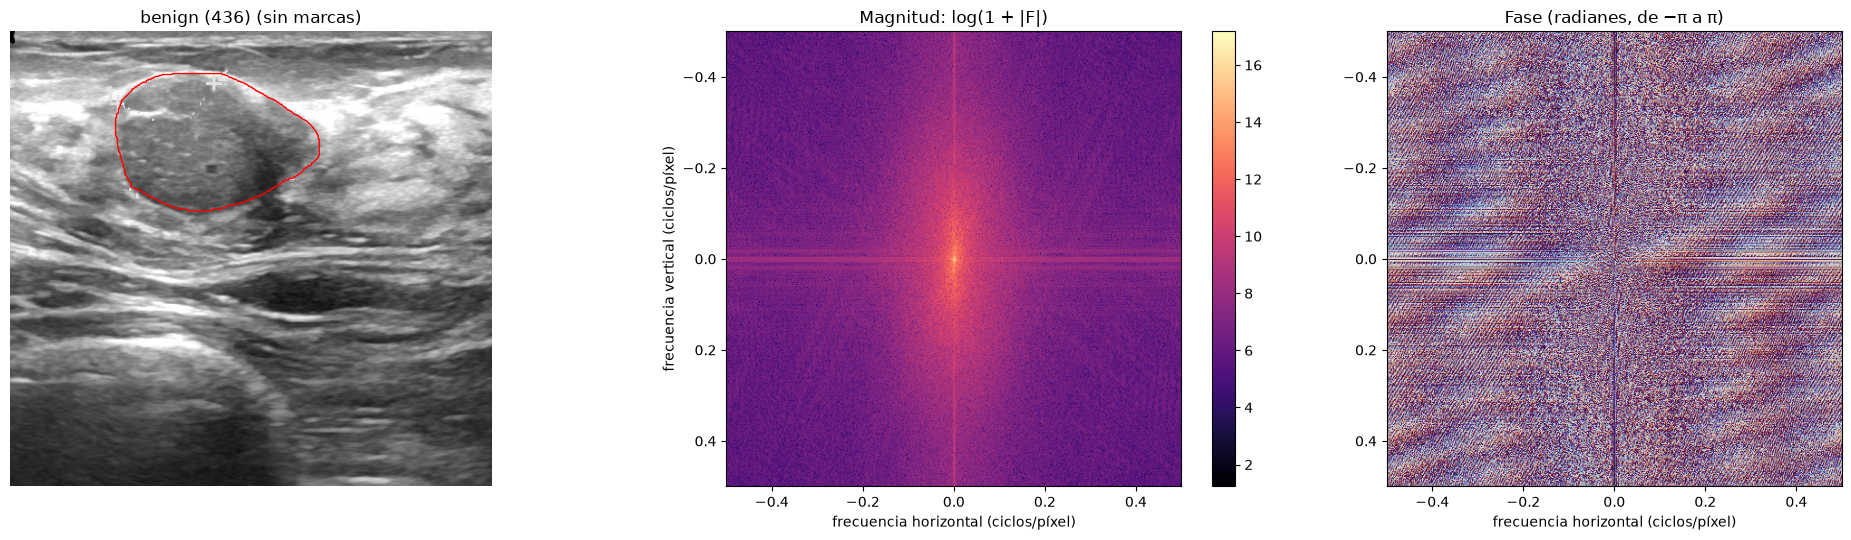

In [3]:
EJEMPLO = "benign (436)"
img, mascara, marcas = cargar_limpio(casos.loc[EJEMPLO])
F = dominios.espectro(img)                      # FFT centrada

fig, axes = plt.subplots(1, 3, figsize=(20, 5.5))
axes[0].imshow(img, cmap="gray", vmin=0, vmax=255)
axes[0].contour(mascara, levels=[0.5], colors="red", linewidths=1)
axes[0].set_title(f"{EJEMPLO} (sin marcas)")

alto, ancho = img.shape
extension = [-0.5, 0.5, 0.5, -0.5]                # ejes en ciclos/píxel
h = axes[1].imshow(np.log1p(np.abs(F)), cmap="magma", extent=extension)
axes[1].set_title("Magnitud: log(1 + |F|)")
axes[1].set_xlabel("frecuencia horizontal (ciclos/píxel)")
axes[1].set_ylabel("frecuencia vertical (ciclos/píxel)")
plt.colorbar(h, ax=axes[1], fraction=0.04)

axes[2].imshow(np.angle(F), cmap="twilight", extent=extension)
axes[2].set_title("Fase (radianes, de −π a π)")
axes[2].set_xlabel("frecuencia horizontal (ciclos/píxel)")
for ax in axes[:1]:
    ax.axis("off")
plt.tight_layout()
plt.show()

**Qué vemos:**
- La magnitud está **concentrada en el centro**: casi toda la "energía" de la ecografía está en las frecuencias bajas, o sea, en variaciones lentas del brillo. Lo cuantificamos en la sección 5.2.
- El espectro es **alargado en vertical**: la imagen varía más rápido de arriba hacia abajo que de izquierda a derecha. Tiene sentido: el tejido mamario se dispone en **capas horizontales** (como las fibras que vimos en la Parte 1) y el grano del *speckle* es más ancho que alto (Parte 2).
- Aparece una **cruz** brillante sobre los ejes. No es tejido: la FFT trata la imagen como si se repitiera periódicamente, y el salto entre el borde de arriba y el de abajo (y entre izquierda y derecha) aporta energía a lo largo de los ejes. Es la razón por la que, más adelante, filtramos con *padding* por reflexión y calculamos el espectro con una ventana de Hann.
- La **fase** parece ruido: a simple vista no se puede interpretar.

### 1.1 ¿Dónde está la información: en la magnitud o en la fase?

Un experimento clásico (clase de Mejoramiento): reconstruimos la imagen con la transformada inversa usando
1. **solo la magnitud** (fase = 0 en todos los puntos);
2. **solo la fase** (magnitud = 1 en todos los puntos);
3. la **magnitud de otra ecografía** con la **fase de esta**.

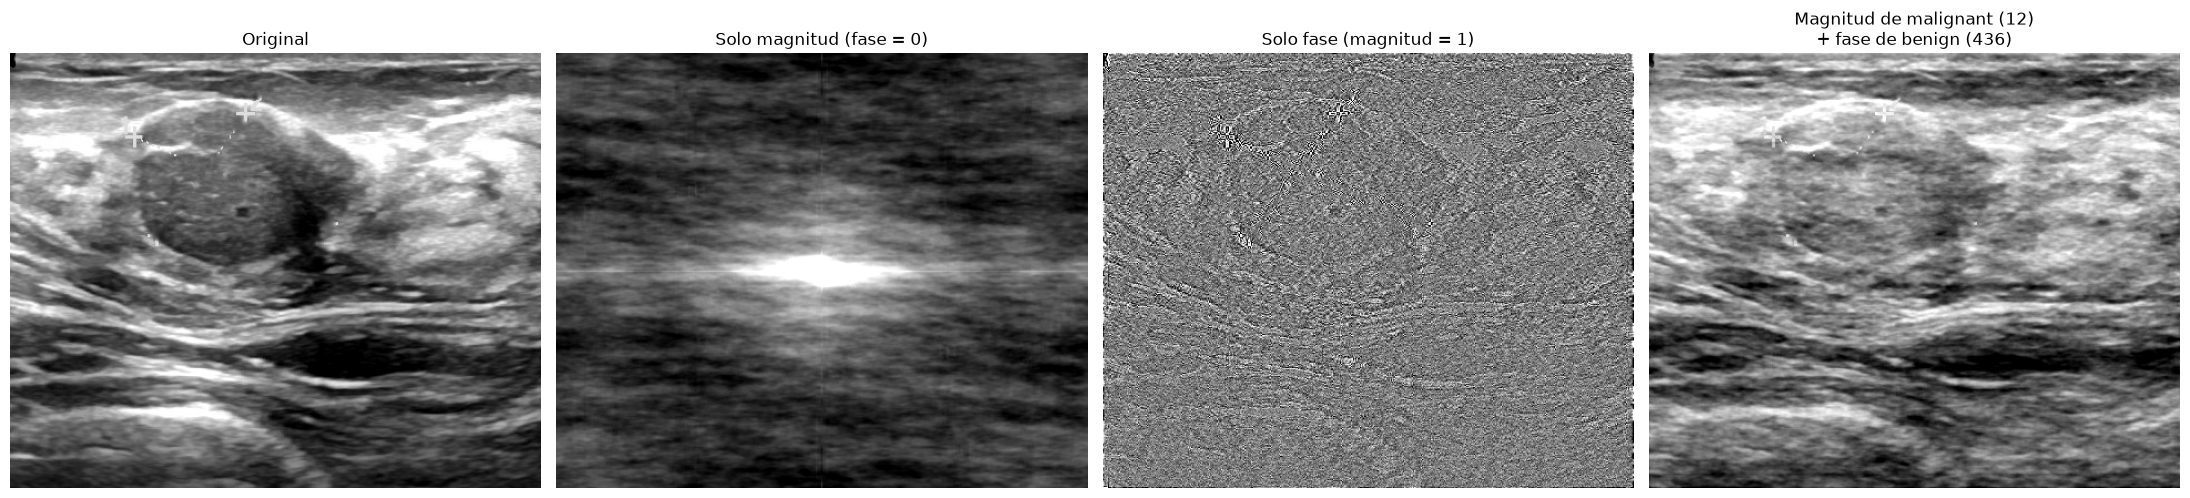

In [4]:
OTRA = "malignant (12)"
img_otra, _, _ = cargar_limpio(casos.loc[OTRA])
# recortamos las dos al mismo tamaño (la esquina superior izquierda común) para poder cruzarlas
alto_c, ancho_c = min(img.shape[0], img_otra.shape[0]), min(img.shape[1], img_otra.shape[1])
a = img[:alto_c, :ancho_c].astype(float)
b = img_otra[:alto_c, :ancho_c].astype(float)
Fa, Fb = np.fft.fft2(a), np.fft.fft2(b)

solo_magnitud = np.real(np.fft.ifft2(np.abs(Fa)))
solo_fase = np.real(np.fft.ifft2(np.exp(1j * np.angle(Fa))))
cruzada = np.real(np.fft.ifft2(np.abs(Fb) * np.exp(1j * np.angle(Fa))))

fig, axes = plt.subplots(1, 4, figsize=(22, 5))
for ax, (titulo, im) in zip(axes, [("Original", a),
                                   ("Solo magnitud (fase = 0)", np.fft.fftshift(solo_magnitud)),
                                   ("Solo fase (magnitud = 1)", solo_fase),
                                   (f"Magnitud de {OTRA}\n+ fase de {EJEMPLO}", cruzada)]):
    lim = np.percentile(im, [1, 99])
    ax.imshow(im, cmap="gray", vmin=lim[0], vmax=lim[1])
    ax.set_title(titulo)
    ax.axis("off")
plt.tight_layout()
plt.show()

**Qué vemos:**
- Con **solo la magnitud** no se reconoce nada: queda una mancha centrada.
- Con **solo la fase** se reconocen los **contornos**: el borde de la lesión, las capas de tejido y hasta los *calipers* que la Parte 1 no detectó.
- La **imagen cruzada** se parece a `benign (436)`, la imagen que aportó la **fase**, y no a la que aportó la magnitud.

**La estructura (dónde están los bordes) está en la fase;** la magnitud dice cuánta energía hay en cada frecuencia (cuán grueso o fino es el grano, cuánto contraste). Esto es importante para lo que sigue: los seis filtros pasabajos tienen una $H$ **real y positiva** (en los lineales), así que **no tocan la fase**, solo achican la magnitud de las frecuencias altas. Por eso suavizan los bordes pero **no los cambian de lugar**.

## 2. Los seis filtros y cómo los emparejamos

| Dominio | Filtro | Qué hace |
|---|---|---|
| Espacial | **Media** | Reemplaza cada píxel por el promedio de una ventana L × L |
| Espacial | **Gaussiano** | Promedio ponderado: los vecinos cercanos pesan más (campana de desvío σ) |
| Espacial | **Mediana** | Reemplaza cada píxel por la mediana de la ventana. **No es lineal**: no se puede escribir como una multiplicación en frecuencia |
| Frecuencial | **Ideal** | $H = 1$ hasta la frecuencia de corte $D_0$ y $H = 0$ después: corte abrupto |
| Frecuencial | **Butterworth** (orden 2) | $H = 1 / (1 + (D/D_0)^{4})$: transición suave, vale 0,5 en $D_0$ |
| Frecuencial | **Gaussiano** | $H = e^{-D^2 / 2D_0^2}$: transición todavía más suave |

**El problema de comparar dominios.** Cada filtro tiene su propio parámetro (tamaño de ventana, σ, frecuencia de corte). Si los elegimos por separado, un dominio puede "ganar" solo porque le tocó un filtro más fuerte. Por eso los **emparejamos**: definimos tres **niveles de suavizado** σ = 1, 2 y 3 px y, para cada nivel, cada filtro usa el parámetro **equivalente a un gaussiano de desvío σ**:

- **Media y mediana:** ventana L con la misma varianza que la gaussiana. Una ventana de L píxeles tiene varianza $(L^2 - 1)/12$, así que $L \approx \sqrt{12\sigma^2 + 1}$ → L = 3, 7 y 11.
- **Frecuenciales:** la transformada de Fourier de una gaussiana de desvío σ es **otra gaussiana**, de desvío $1/(2\pi\sigma)$. Usamos ese valor como frecuencia de corte de los tres: $D_0$ = 0,159, 0,080 y 0,053 ciclos/píxel. Con esa elección el **gaussiano frecuencial es exactamente el mismo filtro que el gaussiano espacial**, lo que sirve de control.

**Detalle de implementación:** la FFT trata la imagen como si se repitiera periódicamente, así que filtrar en frecuencia mezcla el borde de arriba con el de abajo. Para evitarlo, `dominios.pasabajos()` agranda la imagen reflejándola en los bordes, filtra y recorta (los filtros espaciales hacen lo mismo con sus bordes).

              ventana L (media, mediana)  corte D0 (ciclos/píxel)
nivel σ (px)                                                     
1                                      3                    0.159
2                                      7                    0.080
3                                     11                    0.053


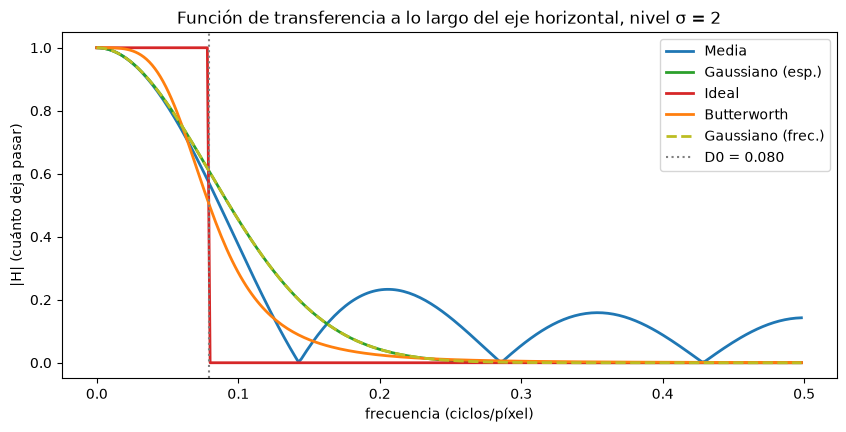

In [5]:
tabla = pd.DataFrame({s: dominios.parametros_equivalentes(s) for s in dominios.SIGMAS}).T
tabla["ventana"] = tabla["ventana"].astype(int)
tabla.index.name = "nivel σ (px)"
tabla.columns = ["ventana L (media, mediana)", "corte D0 (ciclos/píxel)"]
print(tabla.round(3))

# Función de transferencia de cada filtro lineal a lo largo del eje horizontal, para σ = 2.
# Para los espaciales se calcula la FFT de su núcleo (la "respuesta al impulso").
sigma = 2
p = dominios.parametros_equivalentes(sigma)
n = 512
f = np.fft.fftshift(np.fft.fftfreq(n))
impulso = np.zeros((n, n)); impulso[n // 2, n // 2] = 1
H = {
    "media": np.abs(np.fft.fftshift(np.fft.fft2(np.fft.ifftshift(dominios.filtro_media(impulso, p["ventana"]))))),
    "gaussiano": np.abs(np.fft.fftshift(np.fft.fft2(np.fft.ifftshift(dominios.filtro_gaussiano(impulso, sigma))))),
    "ideal": dominios.mascara_pasabajos((n, n), p["corte"], "ideal"),
    "butterworth": dominios.mascara_pasabajos((n, n), p["corte"], "butterworth"),
    "gaussiano_frec": dominios.mascara_pasabajos((n, n), p["corte"], "gaussiano"),
}
fig, ax = plt.subplots(figsize=(10, 4.5))
for nombre, h in H.items():
    estilo = "--" if nombre == "gaussiano_frec" else "-"
    ax.plot(f[n // 2:], h[n // 2, n // 2:], estilo, color=COLORES[nombre], label=NOMBRES[nombre], linewidth=2)
ax.axvline(p["corte"], color="gray", linestyle=":", label=f"D0 = {p['corte']:.3f}")
ax.set_xlabel("frecuencia (ciclos/píxel)")
ax.set_ylabel("|H| (cuánto deja pasar)")
ax.set_title(f"Función de transferencia a lo largo del eje horizontal, nivel σ = {sigma}")
ax.legend()
plt.show()

**Qué vemos:**
- El **gaussiano espacial y el frecuencial se superponen** exactamente: son el mismo filtro.
- El **ideal** corta de golpe en $D_0$. El **Butterworth** deja pasar un poco más que el gaussiano antes de $D_0$ y corta más rápido después.
- La **media** no baja de forma monótona: tiene **lóbulos** que vuelven a dejar pasar frecuencias altas (hasta ~23 % alrededor de 0,2 ciclos/píxel). Es la transformada de una ventana cuadrada (un seno cardinal): promediar con pesos iguales no elimina del todo las variaciones rápidas.
- La **mediana** no aparece porque no es lineal: no tiene función de transferencia.

**Control: el gaussiano en los dos dominios.** Si el emparejamiento está bien hecho, filtrar con el gaussiano espacial y con el gaussiano frecuencial tiene que dar la misma imagen.

In [6]:
for s in dominios.SIGMAS:
    dif = np.abs(dominios.filtrar(img, "gaussiano", s) - dominios.filtrar(img, "gaussiano_frec", s))
    b = 4 * s                                   # el núcleo gaussiano llega hasta ~4σ px
    print(f"σ = {s}: diferencia máxima {dif.max():5.2f} niveles de gris en toda la imagen, "
          f"{dif[b:-b, b:-b].max():.3f} sin los {b} px del borde")

σ = 1: diferencia máxima  6.40 niveles de gris en toda la imagen, 0.070 sin los 4 px del borde
σ = 2: diferencia máxima 10.20 niveles de gris en toda la imagen, 0.003 sin los 8 px del borde
σ = 3: diferencia máxima 18.69 niveles de gris en toda la imagen, 0.005 sin los 12 px del borde


**Qué vemos:** lejos del borde de la imagen las dos versiones del gaussiano coinciden (diferencias menores a 0,1 niveles de gris, error numérico). Solo difieren en los **primeros píxeles del borde** (hasta ~19 niveles), porque cada método completa la imagen "por fuera" de forma distinta para poder filtrar los píxeles del borde: el gaussiano espacial repite el último píxel y nuestro filtrado en frecuencia refleja la imagen. Las mediciones de la sección 4 se hacen alrededor de la lesión y en parches de tejido, así que casi no usan esos píxeles. **El emparejamiento está bien hecho.**

## 3. Cómo se ve cada filtro

### 3.1 La imagen filtrada

Zoom sobre la lesión de `benign (436)`, con los seis filtros en los tres niveles de suavizado.

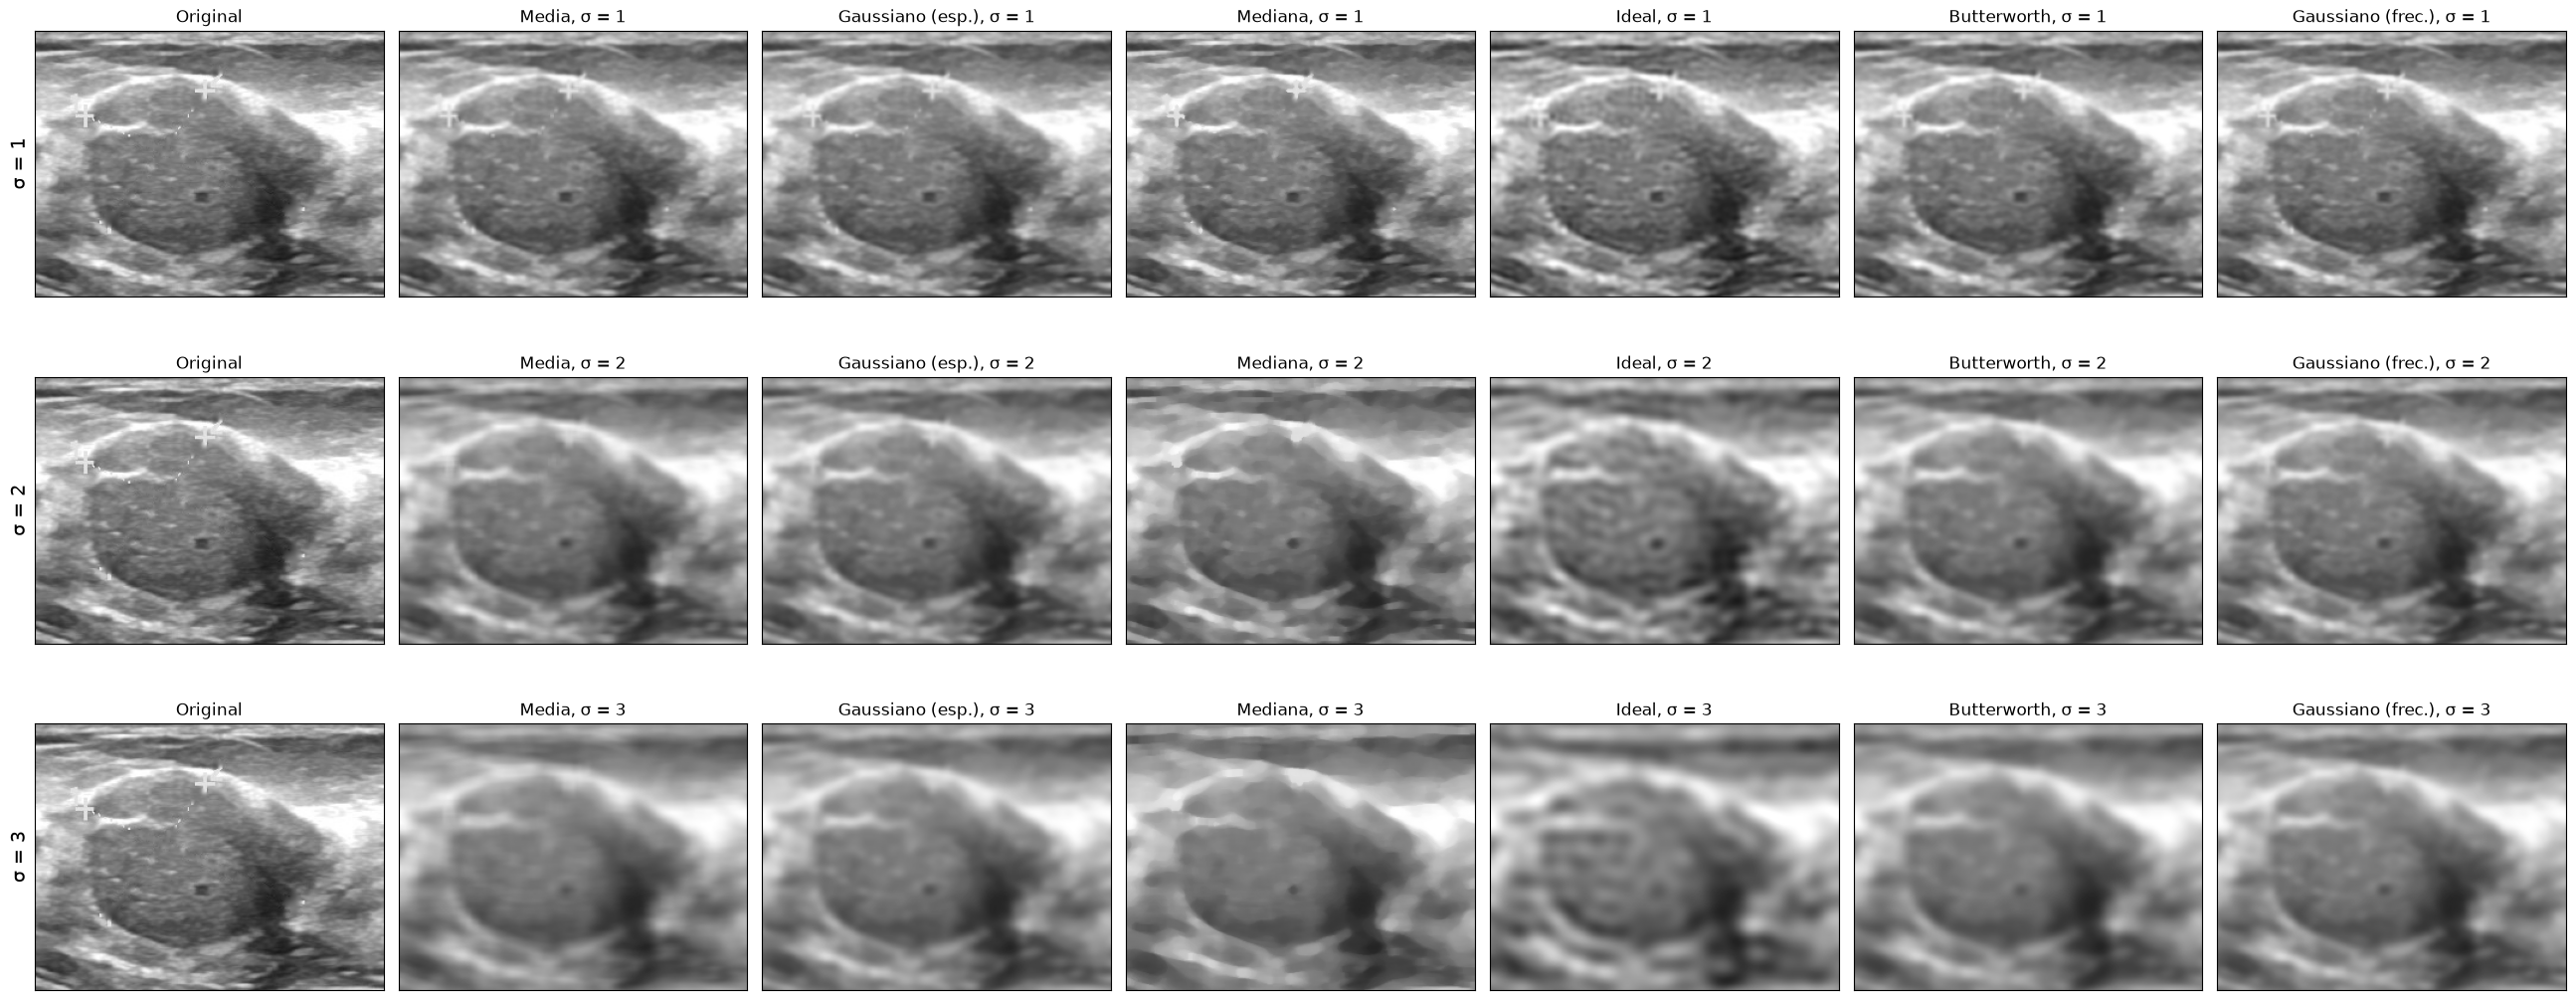

In [7]:
zona = dominios.recorte(mascara, margen=40)
filtros = list(dominios.FILTROS)

fig, axes = plt.subplots(3, 7, figsize=(26, 11))
for fila, s in zip(axes, dominios.SIGMAS):
    fila[0].imshow(img[zona], cmap="gray", vmin=0, vmax=255)
    fila[0].set_title("Original")
    fila[0].set_ylabel(f"σ = {s}", fontsize=14)
    for ax, filtro in zip(fila[1:], filtros):
        ax.imshow(dominios.filtrar(img, filtro, s)[zona], cmap="gray", vmin=0, vmax=255)
        ax.set_title(f"{NOMBRES[filtro]}, σ = {s}")
    for ax in fila:
        ax.set_xticks([]); ax.set_yticks([])
plt.tight_layout()
plt.show()

**Qué vemos:**
- Con **σ = 1** las seis imágenes son casi iguales a la original: el grano del *speckle* casi no cambia.
- Con **σ = 2 y 3**, los filtros **lineales** (media, gaussianos, Butterworth) dan imágenes parecidas: todo se vuelve más borroso, incluido el borde de la lesión.
- La **mediana** se ve distinta: deja **zonas planas separadas por bordes netos**, como una acuarela. Con σ = 3 el efecto es fuerte y aparecen "manchas" que no estaban en la original.
- El **ideal** agrega un patrón de **ondas** dentro de la lesión y en el tejido (se ve mejor con σ = 3): es textura **artificial**, que el filtro inventó.
- Siguen viéndose algunos *calipers* que la Parte 1 no detectó (los que estaban sobre tejido claro).

### 3.2 Perfil de intensidad a través del borde

Como en la Parte 1, tomamos los píxeles a lo largo de una línea horizontal que **cruza la lesión** por su centro y graficamos el nivel de gris. Comparamos la imagen original con tres filtros en el nivel más fuerte (σ = 3), donde las diferencias se ven mejor.

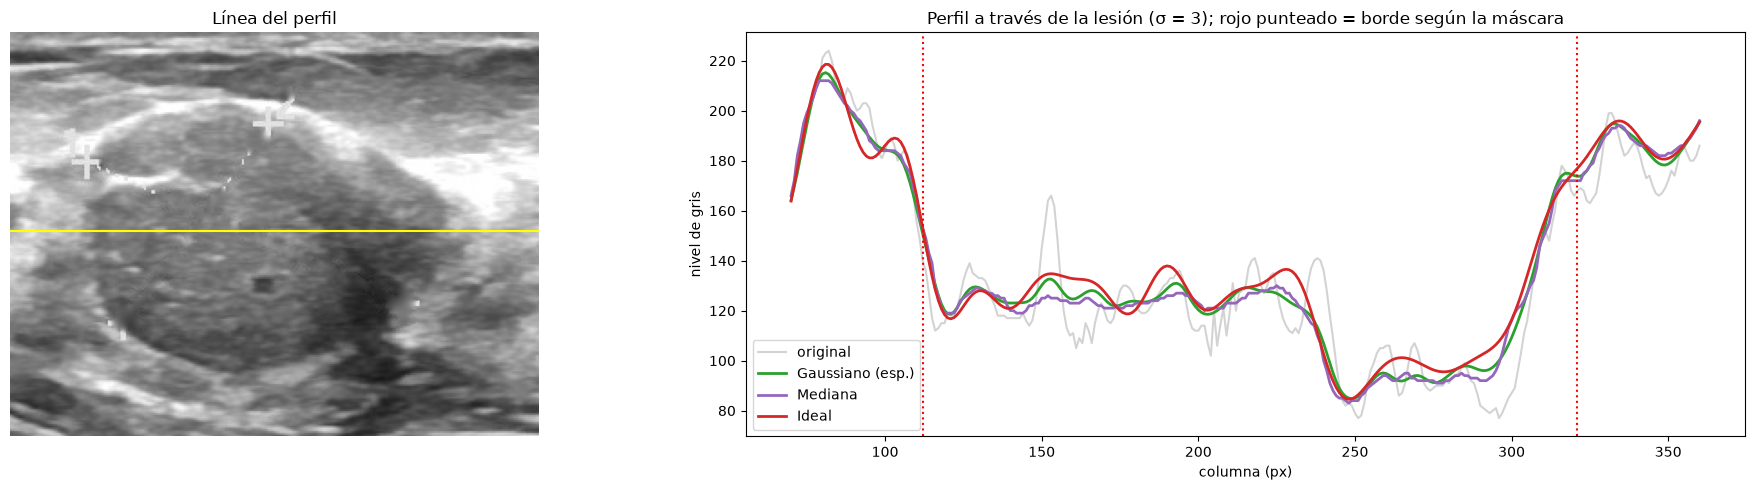

In [8]:
filas_les, cols_les = np.nonzero(mascara)
y = int(filas_les.mean())                                       # fila que pasa por el centro de la lesión
x0, x1 = max(cols_les.min() - 40, 0), min(cols_les.max() + 40, img.shape[1])
borde_izq, borde_der = np.nonzero(mascara[y])[0][[0, -1]]

fig, axes = plt.subplots(1, 2, figsize=(20, 5))
axes[0].imshow(img[zona], cmap="gray", vmin=0, vmax=255)
axes[0].plot([x0 - zona[1].start, x1 - zona[1].start], [y - zona[0].start] * 2, color="yellow")
axes[0].set_title("Línea del perfil")
axes[0].axis("off")

xs = np.arange(x0, x1)
axes[1].plot(xs, img[y, x0:x1], color="lightgray", label="original")
for filtro in ["gaussiano", "mediana", "ideal"]:
    axes[1].plot(xs, dominios.filtrar(img, filtro, 3)[y, x0:x1], color=COLORES[filtro], label=NOMBRES[filtro], linewidth=2)
for b in (borde_izq, borde_der):
    axes[1].axvline(b, color="red", linestyle=":")
axes[1].set_xlabel("columna (px)")
axes[1].set_ylabel("nivel de gris")
axes[1].set_title("Perfil a través de la lesión (σ = 3); rojo punteado = borde según la máscara")
axes[1].legend()
plt.tight_layout()
plt.show()

**Qué vemos:**
- Los tres filtros siguen el **escalón grande** del borde (alrededor de la columna 112) y se llevan los picos y valles rápidos del *speckle*.
- El **ideal oscila**: cerca del borde izquierdo baja y sube (columnas ~97–105) y dentro de la lesión forma ondas que no están en la original. Es el **fenómeno de Gibbs** (*ringing*): un corte abrupto en frecuencia produce ondulaciones alrededor de cada salto de la imagen.
- La **mediana** deja **tramos más planos** y escalones más netos (por ejemplo, entre las columnas 250 y 290), mientras el gaussiano redondea todo.

### 3.3 Qué se lleva cada filtro (pasa-altos)

Lo que un pasabajos **saca** es la diferencia **original − filtrada**. Para los filtros lineales, esa diferencia es exactamente la imagen filtrada con el **pasa-altos complementario** ($1 - H$). Mirarla dice si el filtro se llevó solo el grano del *speckle* (que debería verse como ruido sin estructura) o también **bordes** de la lesión (que se verían como un contorno).

En gris = 0 (no cambió); claro = el filtro bajó ese píxel; oscuro = lo subió.

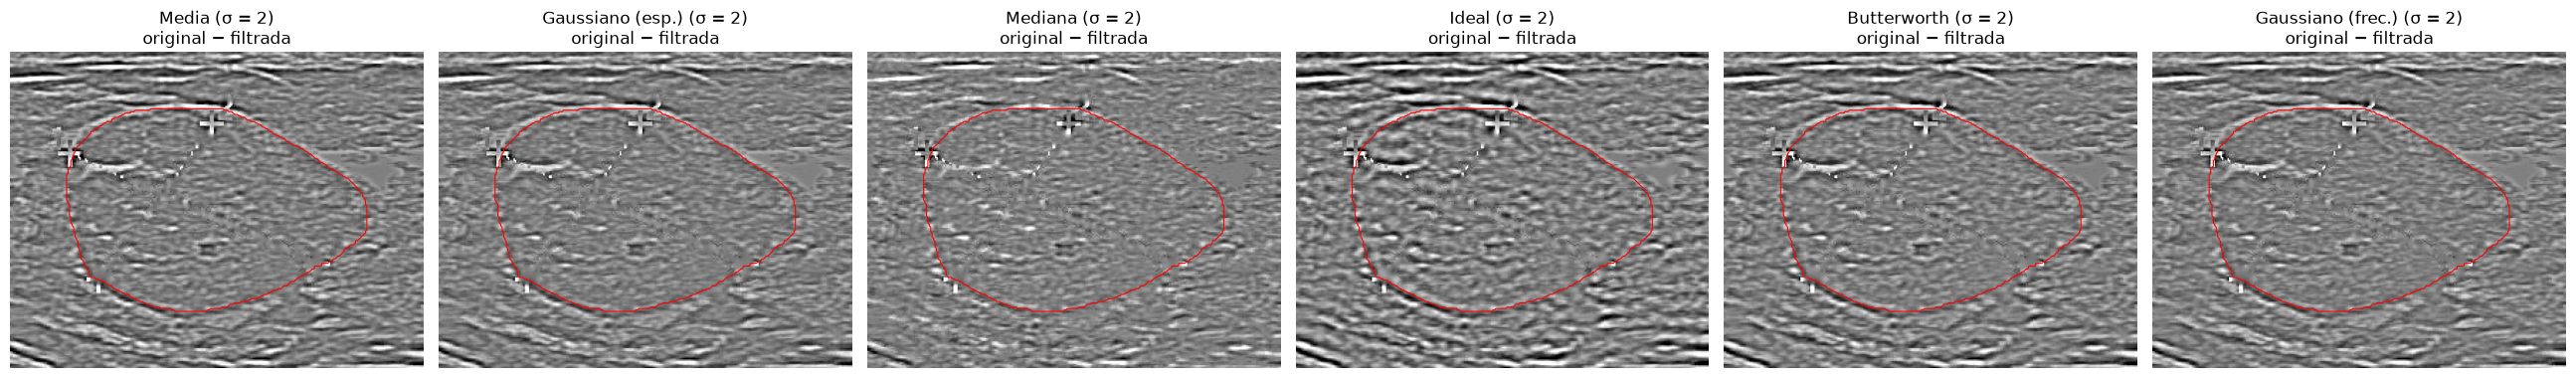

In [9]:
fig, axes = plt.subplots(1, 6, figsize=(26, 5))
for ax, filtro in zip(axes, filtros):
    residuo = img.astype(float) - dominios.filtrar(img, filtro, 2)
    ax.imshow(residuo[zona], cmap="gray", vmin=-40, vmax=40)
    ax.contour(mascara[zona], levels=[0.5], colors="red", linewidths=0.8)
    ax.set_title(f"{NOMBRES[filtro]} (σ = 2)\noriginal − filtrada")
    ax.axis("off")
plt.tight_layout()
plt.show()

**Qué vemos:**
- Lo que sacan todos los filtros es sobre todo **grano fino** (el *speckle*), las **fibras finas** brillantes y los restos de las **marcas** que la Parte 1 no borró.
- El **contorno de la lesión no aparece** como una línea marcada en ningún residuo: con σ = 2 los filtros casi no se llevan el escalón grande del borde, sino el grano que lo rodea.
- El residuo del **ideal** tiene un **patrón ondulado** regular, que es la huella del *ringing*.

### 3.4 Bordes con Canny

El detector de **Canny** (clase de Mejoramiento) marca los bordes como líneas de un píxel: calcula el gradiente, se queda con los máximos locales a lo largo de la dirección del gradiente y une los tramos con dos umbrales (histéresis). Usamos los mismos parámetros en todas las imágenes (suavizado interno σ = 1 y umbrales en los percentiles 90 y 97 del gradiente) y vemos si el **contorno de la lesión** aparece continuo o se pierde entre los bordes del *speckle*.

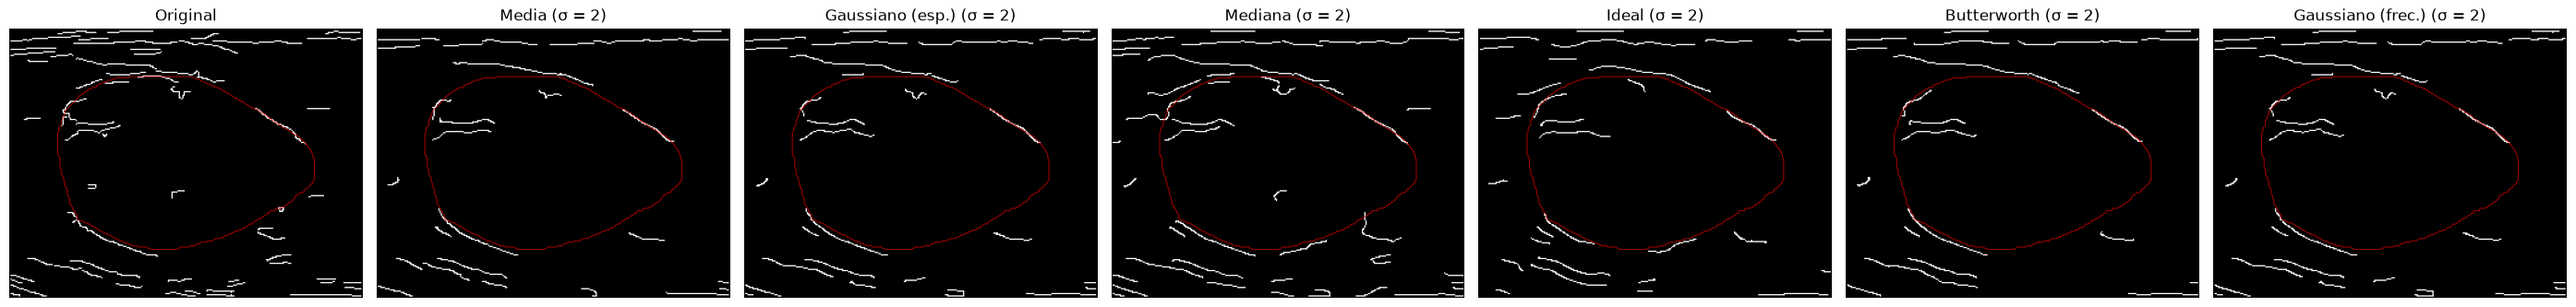

In [10]:
fig, axes = plt.subplots(1, 7, figsize=(28, 4.8))
for ax, (titulo, im) in zip(axes, [("Original", img.astype(float))] +
                            [(f"{NOMBRES[f]} (σ = 2)", dominios.filtrar(img, f, 2)) for f in filtros]):
    bordes = feature.canny(im[zona], sigma=1, low_threshold=0.90, high_threshold=0.97, use_quantiles=True)
    ax.imshow(bordes, cmap="gray")
    ax.contour(mascara[zona], levels=[0.5], colors="red", linewidths=0.8, alpha=0.6)
    ax.set_title(titulo)
    ax.axis("off")
plt.tight_layout()
plt.show()

**Qué vemos:**
- En la **original** Canny encuentra muchos bordes cortos que son *speckle* y fibras, incluso **dentro de la lesión**, y el contorno de la lesión queda cortado en pedazos.
- En las **filtradas** desaparecen casi todos los bordes falsos de adentro de la lesión, y los contornos izquierdo e inferior quedan **más continuos**.
- **Ningún filtro recupera el lado derecho** de la lesión, donde se funde con la sombra. Eso no es ruido sino **falta de contraste real**: filtrar no lo puede arreglar.
- A simple vista las diferencias **entre** filtros son chicas. Por eso las medimos en todo el dataset.

## 4. Medición en las 647 imágenes con lesión

Para cada imagen con lesión aplicamos los 6 filtros en los 3 niveles (18 imágenes filtradas) y medimos, con `dominios.medir_caso()`:

| Métrica | Qué mide | Dónde | Mejor si |
|---|---|---|---|
| **Ganancia de ENL** | ENL = $(\mu/\sigma)^2$ (número equivalente de *looks*): cuánto se redujo la variación relativa del *speckle*. Ganancia = ENL filtrada / ENL original **en los mismos parches** (la Parte 2 mostró que μ/σ depende del brillo, así que no comparamos valores absolutos entre imágenes) | 5 parches de tejido homogéneo de 32 × 32 px, lejos de la lesión y de las marcas (`ruido.extraer_parches` de la Parte 2) | más alta |
| **Borde relativo** | Gradiente de Sobel medio sobre el contorno de la lesión, dividido por el de la imagen original. Cuánto del "salto" del borde sobrevive | banda de 3 px sobre el borde de la máscara | más cerca de 1 |
| **Contraste de borde** | Gradiente sobre el contorno / gradiente en el tejido de alrededor. Cuánto **resalta** el borde de la lesión sobre los "bordes" falsos del *speckle* | banda del borde y anillo de tejido a 5–20 px | más alto |
| **PSD** | Densidad espectral de potencia filtrada / original, por frecuencia: qué frecuencias quitó cada filtro | imagen completa | — |
| **GLCM** | Contraste, homogeneidad, energía y correlación (32 niveles, distancias 1 y 4 px, promedio de 4 direcciones) | interior de la lesión y anillo de tejido | que la lesión y el tejido sigan siendo distintos |
| **PSNR / SSIM** | Cuánto se parece la imagen filtrada a la original | recorte alrededor de la lesión | ver sección 5.5 |

Las regiones, sobre el ejemplo:

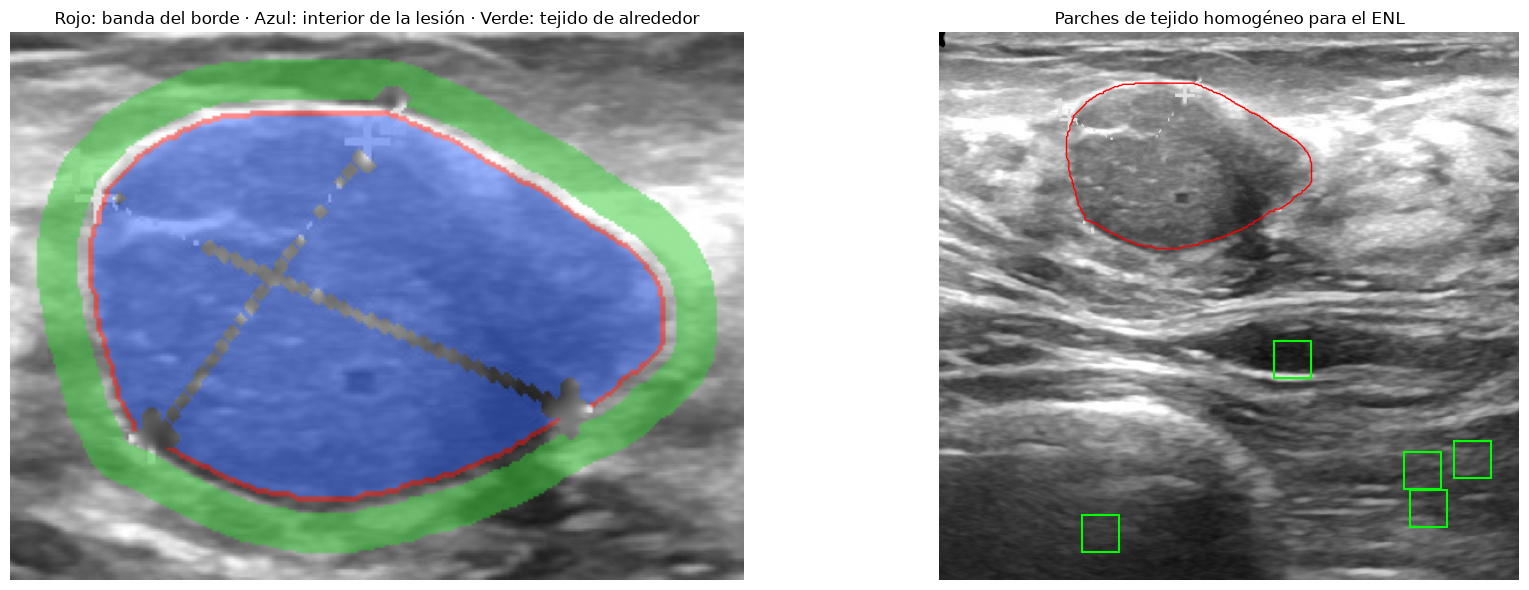

In [11]:
z = dominios.recorte(mascara)
m, mk = mascara[z], marcas[z]
banda = dominios.contorno(m) & ~mk
lesion = m & ~dominios.contorno(m) & ~mk
tejido = dominios.anillo(m) & ~mk

rgb = np.dstack([img[z]] * 3).astype(float) / 255
for region, color in [(lesion, (0.2, 0.4, 1)), (tejido, (0.2, 0.8, 0.2)), (banda, (1, 0.1, 0.1))]:
    rgb[region] = 0.5 * rgb[region] + 0.5 * np.array(color)

_, esquinas = ruido.extraer_parches(img, mascara | marcas, n=5, rng=np.random.default_rng(SEED))
fig, axes = plt.subplots(1, 2, figsize=(18, 6))
axes[0].imshow(rgb)
axes[0].set_title("Rojo: banda del borde · Azul: interior de la lesión · Verde: tejido de alrededor")
axes[0].axis("off")
axes[1].imshow(img, cmap="gray", vmin=0, vmax=255)
for (yy, xx) in esquinas:
    axes[1].add_patch(plt.Rectangle((xx, yy), 32, 32, fill=False, edgecolor="lime", linewidth=1.5))
axes[1].contour(mascara, levels=[0.5], colors="red", linewidths=1)
axes[1].set_title("Parches de tejido homogéneo para el ENL")
axes[1].axis("off")
plt.tight_layout()
plt.show()

El cálculo tarda alrededor de **20 minutos** (unos 2 s por imagen). Los resultados se guardan en `outputs/dominios/` (que no se sube a GitHub): si el archivo ya existe se lee directamente. Para recalcular, poner `RECALCULAR = True`.

In [12]:
RECALCULAR = False
carpeta = cfg["OUTPUT_DIR"] / "dominios"
archivo_metricas = carpeta / "metricas.csv"
archivo_psd = carpeta / "psd_relativa.npz"

if archivo_metricas.exists() and archivo_psd.exists() and not RECALCULAR:
    metricas = pd.read_csv(archivo_metricas)
    datos_psd = np.load(archivo_psd)
    claves_psd = [tuple(k.split("|")) for k in datos_psd["claves"]]
    psd_relativa = datos_psd["psd"]
    print("Resultados leídos de", archivo_metricas)
else:
    rng = np.random.default_rng(SEED)
    filas, psd_relativa = [], []
    for i, (id_caso, caso) in enumerate(con_lesion.iterrows()):
        im, masc, mk = cargar_limpio(caso)
        filas_caso, perfiles = dominios.medir_caso(im, masc, mk, rng)
        for fila in filas_caso:
            fila.update(id=id_caso, clase=caso["clase"])
        filas.extend(filas_caso)
        psd_relativa.append(np.array(list(perfiles.values())))
        if (i + 1) % 100 == 0:
            print(f"{i + 1} de {len(con_lesion)} imágenes")
    metricas = pd.DataFrame(filas)
    claves_psd = [(f, str(s)) for f, s in perfiles]
    psd_relativa = np.array(psd_relativa)                   # (imágenes, filtro y nivel, frecuencia)
    carpeta.mkdir(parents=True, exist_ok=True)
    metricas.to_csv(archivo_metricas, index=False)
    np.savez(archivo_psd, psd=psd_relativa, claves=np.array(["|".join(k) for k in claves_psd]))

frecuencias, _ = dominios.psd_radial(np.zeros((64, 64)))
print(f"{metricas['id'].nunique()} imágenes, {len(metricas)} filas (original + 18 filtradas por imagen)")

Resultados leídos de C:\PSIB\TPI\PSIB_TPI_GRUPO_13\outputs\dominios\metricas.csv
647 imágenes, 12293 filas (original + 18 filtradas por imagen)


## 5. Resultados

### 5.1 Suavizado y bordes

Para cada filtro y nivel, la **mediana** sobre las 647 imágenes de cada métrica (usamos la mediana, como en la Parte 2, porque no se deja arrastrar por imágenes raras).

In [13]:
filtradas = metricas[metricas["filtro"] != "original"].copy()
filtradas["nombre"] = filtradas["filtro"].map(NOMBRES)

resumen = (filtradas.groupby(["sigma", "dominio", "nombre"], sort=False)
           [["ganancia_enl", "borde_relativo", "contraste_borde"]].median().round(2))
contraste_original = metricas.loc[metricas["filtro"] == "original", "contraste_borde"].median()
print(f"Contraste de borde en la imagen original (mediana): {contraste_original:.2f}\n")
resumen

Contraste de borde en la imagen original (mediana): 1.28



,,,ganancia_enl,borde_relativo,contraste_borde
sigma,dominio,nombre,,,
1,espacial,Media,1.14,0.86,1.35
2,espacial,Media,1.56,0.63,1.53
3,espacial,Media,2.08,0.49,1.59
1,espacial,Gaussiano (esp.),1.19,0.83,1.37
2,espacial,Gaussiano (esp.),1.53,0.64,1.53
3,espacial,Gaussiano (esp.),1.94,0.53,1.61
1,espacial,Mediana,1.08,0.90,1.34
2,espacial,Mediana,1.42,0.69,1.57
3,espacial,Mediana,1.85,0.56,1.75


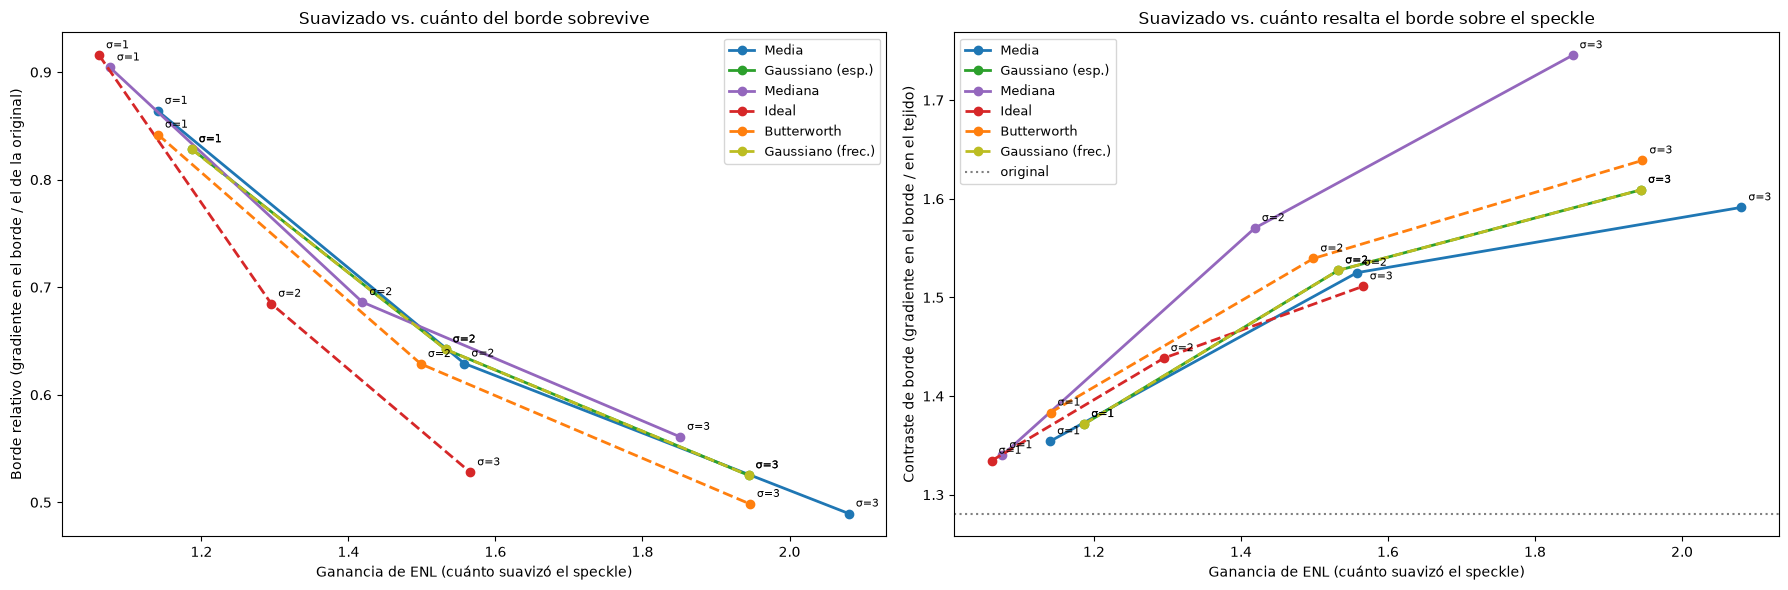

In [14]:
fig, axes = plt.subplots(1, 2, figsize=(18, 6))
for filtro in filtros:
    datos = filtradas[filtradas["filtro"] == filtro].groupby("sigma")[["ganancia_enl", "borde_relativo", "contraste_borde"]].median()
    estilo = "--" if dominios.FILTROS[filtro] == "frecuencial" else "-"
    for ax, col in zip(axes, ["borde_relativo", "contraste_borde"]):
        ax.plot(datos["ganancia_enl"], datos[col], estilo + "o", color=COLORES[filtro], label=NOMBRES[filtro], linewidth=2)
        for s, fila in datos.iterrows():
            ax.annotate(f"σ={s}", (fila["ganancia_enl"], fila[col]), textcoords="offset points", xytext=(5, 5), fontsize=8)
axes[1].axhline(contraste_original, color="gray", linestyle=":", label="original")
axes[0].set_ylabel("Borde relativo (gradiente en el borde / el de la original)")
axes[1].set_ylabel("Contraste de borde (gradiente en el borde / en el tejido)")
for ax in axes:
    ax.set_xlabel("Ganancia de ENL (cuánto suavizó el speckle)")
    ax.legend(fontsize=9)
axes[0].set_title("Suavizado vs. cuánto del borde sobrevive")
axes[1].set_title("Suavizado vs. cuánto resalta el borde sobre el speckle")
plt.tight_layout()
plt.show()

**Qué vemos:**
- **Todos los filtros mejoran el contraste de borde** respecto de la original (mediana 1,28), y más cuanto más fuerte es el filtro: bajan más el gradiente del *speckle* (en el tejido) que el del borde. Pero el **borde relativo cae**: con σ = 3 el salto del borde queda en la mitad (0,49 a 0,56). El filtro también suaviza el borde, solo que menos que el ruido.
- **Las ganancias de ENL son chicas:** como mucho ~2, con ventanas de hasta 11 × 11 = 121 píxeles. Si los píxeles del *speckle* fueran independientes, promediar 49 píxeles (7 × 7) multiplicaría el ENL por ~49, y da 1,5. Es lo que anticipaba la Parte 2: el *speckle* de BUSI forma **granos de varios píxeles** (está correlacionado), así que una ventana chica promedia pocos granos distintos. Además, parte de la variación de los parches son fibras, que no son ruido.
- **Entre los filtros lineales emparejados, los resultados son muy parecidos.** El gaussiano espacial y el frecuencial dan **exactamente** lo mismo. El Butterworth resalta un poco más el borde que el gaussiano (y en σ = 2 suaviza un poco menos). La media suaviza algo más.
- El **ideal es el peor en todo**: con el mismo corte suaviza menos (ENL 1,57 en σ = 3 contra ~1,95 de los otros lineales) y deja el borde menos resaltado (1,51 contra 1,61–1,64). Su corte abrupto no suma suavizado: suma *ringing*.
- La **mediana** es distinta a todos: **con el mismo suavizado, resalta más el borde** (su curva está por encima de todas en el gráfico de la derecha). Con σ = 3 llega a un contraste de borde de **1,75**, contra 1,61–1,64 de los mejores lineales, con un ENL parecido (1,85 contra 1,94). A igual σ suaviza un poco menos que los lineales.

**Respuesta a la pregunta "¿espacial o frecuencial?":** para los filtros lineales, **el dominio no importa**. Un mismo filtro da el mismo resultado aplicado de las dos formas (el control del gaussiano lo muestra). Lo que importa es la **forma** de la función de transferencia: las transiciones suaves (gaussiano, Butterworth) funcionan bien y el corte abrupto (ideal) funciona mal. La única diferencia real entre dominios es que **la mediana solo existe en el dominio espacial**, porque no es lineal, y es justamente la que mejor preserva los bordes.

**¿Las diferencias son reales?** Comparamos los filtros de a pares **imagen por imagen** con la prueba de Wilcoxon de rangos con signo (la versión pareada de Mann-Whitney, como en la Parte 1), en el nivel σ = 2.

In [15]:
ancha = filtradas[filtradas["sigma"] == 2].pivot(index="id", columns="filtro", values=["ganancia_enl", "contraste_borde"])
pares = [("mediana", "gaussiano"), ("mediana", "media"), ("gaussiano", "butterworth"),
         ("gaussiano", "ideal"), ("butterworth", "ideal"), ("media", "gaussiano")]
for metrica in ["ganancia_enl", "contraste_borde"]:
    print(f"--- {metrica} (σ = 2) ---")
    for a, b in pares:
        x, y = ancha[metrica][a], ancha[metrica][b]
        p = wilcoxon(x, y).pvalue
        print(f"  {NOMBRES[a]:17s} vs {NOMBRES[b]:17s}: mayor en el {100 * (x > y).mean():3.0f} % de las imágenes, p = {p:.1e}")

--- ganancia_enl (σ = 2) ---
  Mediana           vs Gaussiano (esp.) : mayor en el  10 % de las imágenes, p = 9.7e-91
  Mediana           vs Media            : mayor en el   6 % de las imágenes, p = 2.9e-100
  Gaussiano (esp.)  vs Butterworth      : mayor en el  73 % de las imágenes, p = 1.2e-35
  Gaussiano (esp.)  vs Ideal            : mayor en el 100 % de las imágenes, p = 1.5e-107
  Butterworth       vs Ideal            : mayor en el 100 % de las imágenes, p = 1.3e-107
  Media             vs Gaussiano (esp.) : mayor en el  98 % de las imágenes, p = 1.9e-104
--- contraste_borde (σ = 2) ---
  Mediana           vs Gaussiano (esp.) : mayor en el  73 % de las imágenes, p = 3.1e-48
  Mediana           vs Media            : mayor en el  66 % de las imágenes, p = 4.3e-32
  Gaussiano (esp.)  vs Butterworth      : mayor en el  24 % de las imágenes, p = 2.7e-40
  Gaussiano (esp.)  vs Ideal            : mayor en el  81 % de las imágenes, p = 2.1e-63
  Butterworth       vs Ideal            : may

**Qué vemos:** todas las diferencias son significativas (p < 0,01), aunque algunas son chicas:
- La **mediana** resalta más el borde que el gaussiano en el **73 %** de las imágenes y que la media en el 66 %. A cambio, suaviza menos (el gaussiano tiene más ENL en el 90 % de las imágenes).
- El **Butterworth** resalta más el borde que el gaussiano en el 76 % de las imágenes, y el gaussiano suaviza más en el 73 %: es el mismo compromiso, más chico.
- El **ideal** pierde contra todos: suaviza menos que el gaussiano y el Butterworth en el **100 %** de las imágenes y resalta menos el borde en el 81–94 %.
- **Media vs. gaussiano:** la media suaviza más en el 98 % de las imágenes, pero en contraste de borde son casi iguales (57 %).

### 5.2 Espectro de potencia: qué frecuencias quita cada filtro

Para cada imagen dividimos la PSD de la imagen filtrada por la de la original, frecuencia por frecuencia, y tomamos la mediana sobre las 647 imágenes. Para un filtro **lineal**, ese cociente es $|H|^2$: su función de transferencia (al cuadrado) **medida sobre las ecografías**. Para la **mediana**, que no es lineal, no hay una $H$ teórica: el cociente muestra qué hace "en promedio".

La PSD se calcula con una **ventana de Hann** (`dominios.psd_radial`): sin ella, el salto entre bordes opuestos de la imagen agrega potencia falsa a todas las frecuencias y tapa lo que queremos ver (en ecografía la potencia de las frecuencias altas es ~10⁵ veces menor que la de las bajas).

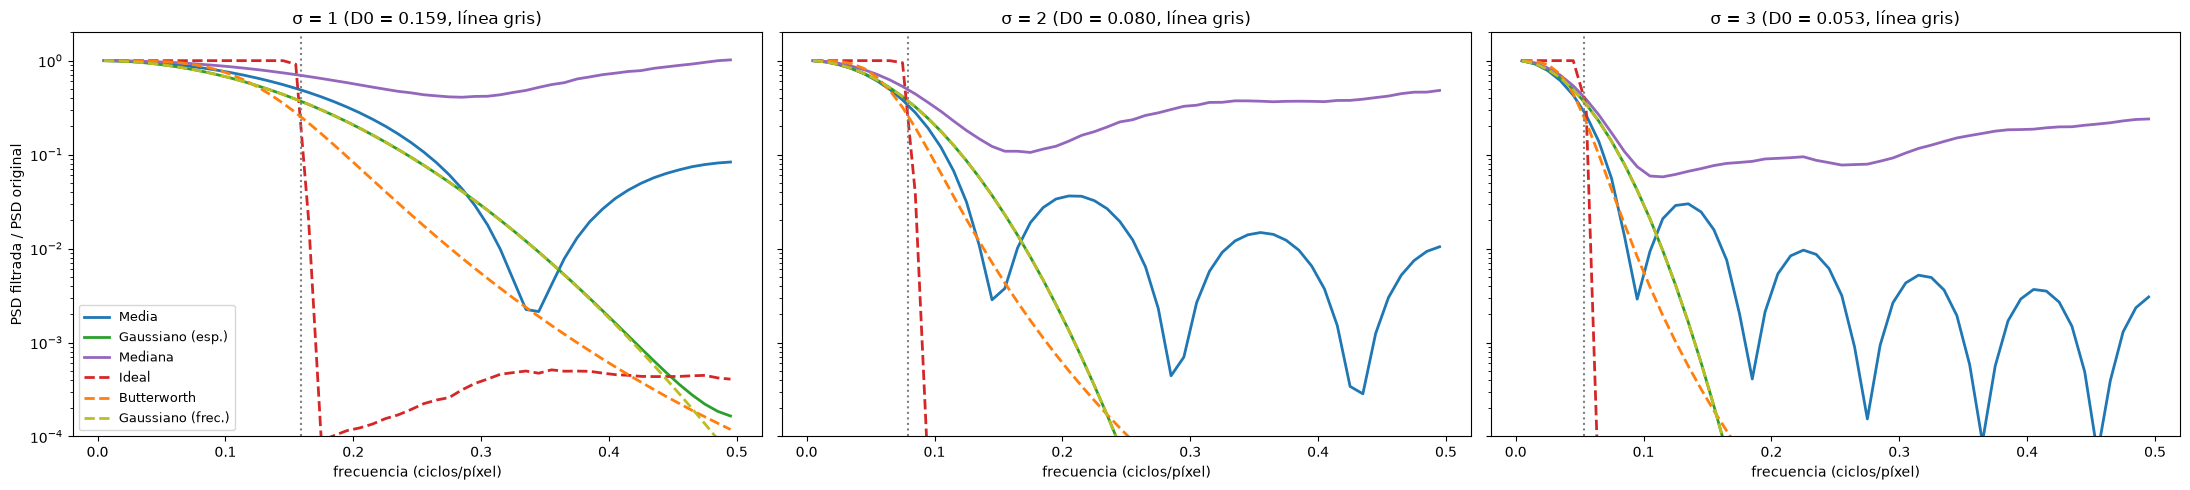

Fracción de la potencia de benign (436) por debajo de 0.05 ciclos/píxel: 98.1 %
Fracción de la potencia de benign (436) por debajo de 0.1 ciclos/píxel: 99.7 %
Fracción de la potencia de benign (436) por debajo de 0.2 ciclos/píxel: 100.0 %


In [16]:
fig, axes = plt.subplots(1, 3, figsize=(22, 5), sharey=True)
for ax, s in zip(axes, dominios.SIGMAS):
    for filtro in filtros:
        k = claves_psd.index((filtro, str(s)))
        estilo = "--" if dominios.FILTROS[filtro] == "frecuencial" else "-"
        ax.plot(frecuencias, np.median(psd_relativa[:, k, :], axis=0), estilo, color=COLORES[filtro],
                label=NOMBRES[filtro], linewidth=2)
    ax.axvline(dominios.parametros_equivalentes(s)["corte"], color="gray", linestyle=":")
    ax.set_yscale("log")
    ax.set_ylim(1e-4, 2)
    ax.set_xlabel("frecuencia (ciclos/píxel)")
    ax.set_title(f"σ = {s} (D0 = {dominios.parametros_equivalentes(s)['corte']:.3f}, línea gris)")
axes[0].set_ylabel("PSD filtrada / PSD original")
axes[0].legend(fontsize=9)
plt.tight_layout()
plt.show()

# potencia original por banda de frecuencia: dónde está la energía de la ecografía
ej = dominios.psd_radial(img)[1]
for lim in [0.05, 0.1, 0.2]:
    print(f"Fracción de la potencia de {EJEMPLO} por debajo de {lim} ciclos/píxel: {100 * ej[frecuencias < lim].sum() / ej.sum():.1f} %")

**Qué vemos:**
- Para los **filtros lineales**, el cociente medido coincide con la forma de su $|H|^2$ (sección 2): el gaussiano espacial y el frecuencial se superponen, el ideal cae a cero justo en $D_0$, el Butterworth cae más rápido que el gaussiano, y la media muestra sus **lóbulos** (ceros en múltiplos de 1/L).
- La **mediana** hace algo que ningún pasabajos puede hacer: **atenúa las frecuencias medias pero conserva buena parte de las altas** (el cociente vuelve a subir hasta 0,2–1 cerca de 0,5 ciclos/píxel). Las frecuencias altas son las que forman los **saltos bruscos**: la mediana aplana las zonas (saca el grano) pero deja bordes netos entre ellas, que es el efecto "acuarela" de la sección 3. Por eso preserva mejor el borde.
- **El 98 % de la potencia de la ecografía está por debajo de 0,05 ciclos/píxel**, y nuestros cortes van de 0,05 a 0,16. Es decir, los filtros actúan sobre una fracción muy chica de la potencia de la imagen. El *speckle* de BUSI tiene un grano grande (el ecógrafo ya suavizó la imagen, Parte 2) y **comparte frecuencias con la anatomía**: no hay una frecuencia de corte que separe el ruido de la lesión. Esto explica por qué las ganancias de ENL son chicas y por qué todos los filtros, al sacar ruido, también suavizan el borde.

### 5.3 Textura: GLCM dentro y fuera de la lesión

La GLCM (matriz de co-ocurrencia) cuenta cuántas veces aparece cada par de niveles de gris a una distancia dada. De ella sacamos:
- **contraste**: diferencia típica entre vecinos (alto = textura áspera);
- **homogeneidad**: qué tanto los vecinos tienen niveles parecidos (alto = textura lisa);
- **energía**: qué tan repetidos son los pares (alto = textura uniforme, pocos niveles);
- **correlación**: qué tan predecible es un píxel a partir de su vecino.

Primero, cómo cambian los valores con cada filtro (σ = 2, distancia 1 px):

In [17]:
props = ["contrast", "homogeneity", "energy", "correlation"]
nombres_props = {"contrast": "contraste", "homogeneity": "homogeneidad", "energy": "energía", "correlation": "correlación"}
cols = [f"{p}_d1_{r}" for p in props for r in ["lesion", "tejido"]]
tabla_glcm = metricas[metricas["sigma"].isin([0, 2])].groupby("filtro", sort=False)[cols].median()
tabla_glcm.index = [NOMBRES.get(f, "Original") for f in tabla_glcm.index]
tabla_glcm.columns = pd.MultiIndex.from_tuples([(nombres_props[c.split("_")[0]], c.split("_")[-1]) for c in cols])
tabla_glcm.round(3)

contraste        homogeneidad        energía         \
                     lesion tejido       lesion tejido  lesion tejido   
Original              0.961  1.335        0.728  0.676   0.192  0.140   
Media                 0.343  0.414        0.853  0.821   0.252  0.187   
Gaussiano (esp.)      0.353  0.427        0.852  0.818   0.251  0.185   
Mediana               0.434  0.566        0.859  0.826   0.256  0.189   
Ideal                 0.395  0.485        0.836  0.797   0.233  0.175   
Butterworth           0.335  0.400        0.856  0.825   0.253  0.187   
Gaussiano (frec.)     0.353  0.427        0.852  0.818   0.251  0.186   

                  correlación         
                       lesion tejido  
Original                0.962  0.970  
Media                   0.984  0.990  
Gaussiano (esp.)        0.983  0.989  
Mediana                 0.980  0.986  
Ideal                   0.982  0.988  
Butterworth             0.984  0.990  
Gaussiano (frec.)       0.983  0.989

**Qué vemos:**
- Filtrar vuelve la textura más **lisa** en las dos regiones: el contraste de la GLCM cae a menos de la mitad (en la lesión, de 0,96 a ~0,34–0,43 con σ = 2) y suben la homogeneidad, la energía y la correlación.
- La lesión y el tejido mantienen el **mismo orden** (el tejido tiene más contraste; la lesión, más homogeneidad y energía), pero la **diferencia se achica mucho**: en la original el contraste es 0,96 en la lesión y 1,34 en el tejido; con el gaussiano, 0,35 y 0,43.
- La **mediana** es la que conserva más contraste en las dos regiones (0,43 y 0,57).

Lo que importa para las Partes 4 y 5 no es el valor en sí, sino si **la lesión y el tejido siguen siendo distinguibles por su textura**. Lo medimos con el **área bajo la curva ROC (AUC)**: tomamos el valor de cada propiedad en la lesión y en el tejido de las 647 imágenes y calculamos la probabilidad de que, eligiendo al azar una lesión y un tejido, la propiedad los ordene bien. AUC = 0,5 es azar; AUC = 1 es separación perfecta. Se calcula con la U de Mann-Whitney: $\text{AUC} = U / (n_1 n_2)$. Como no nos importa el sentido (si la lesión tiene más o menos), reportamos $\max(\text{AUC}, 1 - \text{AUC})$.

In [18]:
def auc(x, y):
    a = mannwhitneyu(x, y).statistic / (len(x) * len(y))
    return max(a, 1 - a)

filas = []
for (filtro, s), grupo in metricas.groupby(["filtro", "sigma"], sort=False):
    fila = {"filtro": NOMBRES.get(filtro, "Original"), "sigma": s}
    for p in props:
        for d in (1, 4):
            les, tej = grupo[f"{p}_d{d}_lesion"].dropna(), grupo[f"{p}_d{d}_tejido"].dropna()
            fila[f"{nombres_props[p]} d{d}"] = auc(les, tej)
    filas.append(fila)
separabilidad = pd.DataFrame(filas).set_index(["sigma", "filtro"]).sort_index(level=0, sort_remaining=False)
separabilidad.round(3)

contraste d1  contraste d4  homogeneidad d1  \
sigma filtro                                                           
0     Original                  0.675         0.691            0.726   
1     Media                     0.664         0.675            0.728   
      Gaussiano (esp.)          0.658         0.668            0.722   
      Mediana                   0.678         0.685            0.730   
      Ideal                     0.665         0.682            0.724   
      Butterworth               0.655         0.669            0.722   
      Gaussiano (frec.)         0.657         0.668            0.722   
2     Media                     0.597         0.599            0.661   
      Gaussiano (esp.)          0.604         0.610            0.666   
      Mediana                   0.621         0.627            0.677   
      Ideal                     0.589         0.603            0.643   
      Butterworth               0.589         0.593            0.652   
      Gaussiano (frec.)         0.604         0.609            0.666   
3     Media                     0.549         0.523            0.592   
      Gaussiano (esp.)          0.560         0.547            0.606   
      Mediana                   0.550         0.551            0.618   
      Ideal                     0.539         0.533            0.575   
      Butterworth               0.541         0.520            0.581   
      Gaussiano (frec.)         0.559         0.547            0.605   

                         homogeneidad d4  energía d1  energía d4  \
sigma filtro                                                       
0     Original                     0.765       0.873       0.873   
1     Media                        0.758       0.878       0.871   
      Gaussiano (esp.)             0.754       0.876       0.869   
      Mediana                      0.767       0.877       0.872   
      Ideal                        0.755       0.877       0.870   
      Butterworth                  0.757       0.877       0.870   
      Gaussiano (frec.)            0.754       0.876       0.869   
2     Media                        0.708       0.855       0.853   
      Gaussiano (esp.)             0.712       0.857       0.855   
      Mediana                      0.729       0.861       0.860   
      Ideal                        0.686       0.841       0.837   
      Butterworth                  0.704       0.851       0.849   
      Gaussiano (frec.)            0.712       0.857       0.855   
3     Media                        0.642       0.810       0.817   
      Gaussiano (esp.)             0.657       0.822       0.827   
      Mediana                      0.674       0.834       0.839   
      Ideal                        0.621       0.792       0.787   
      Butterworth                  0.637       0.802       0.808   
      Gaussiano (frec.)            0.656       0.822       0.827   

                         correlación d1  correlación d4  
sigma filtro                                             
0     Original                    0.605           0.596  
1     Media                       0.624           0.607  
      Gaussiano (esp.)            0.629           0.612  
      Mediana                     0.601           0.598  
      Ideal                       0.620           0.600  
      Butterworth                 0.632           0.611  
      Gaussiano (frec.)           0.630           0.612  
2     Media                       0.670           0.654  
      Gaussiano (esp.)            0.666           0.648  
      Mediana                     0.641           0.635  
      Ideal                       0.678           0.653  
      Butterworth                 0.679           0.661  
      Gaussiano (frec.)           0.666           0.648  
3     Media                       0.688           0.693  
      Gaussiano (esp.)            0.687           0.682  
      Mediana                     0.688           0.684  
      Ideal                       0.706

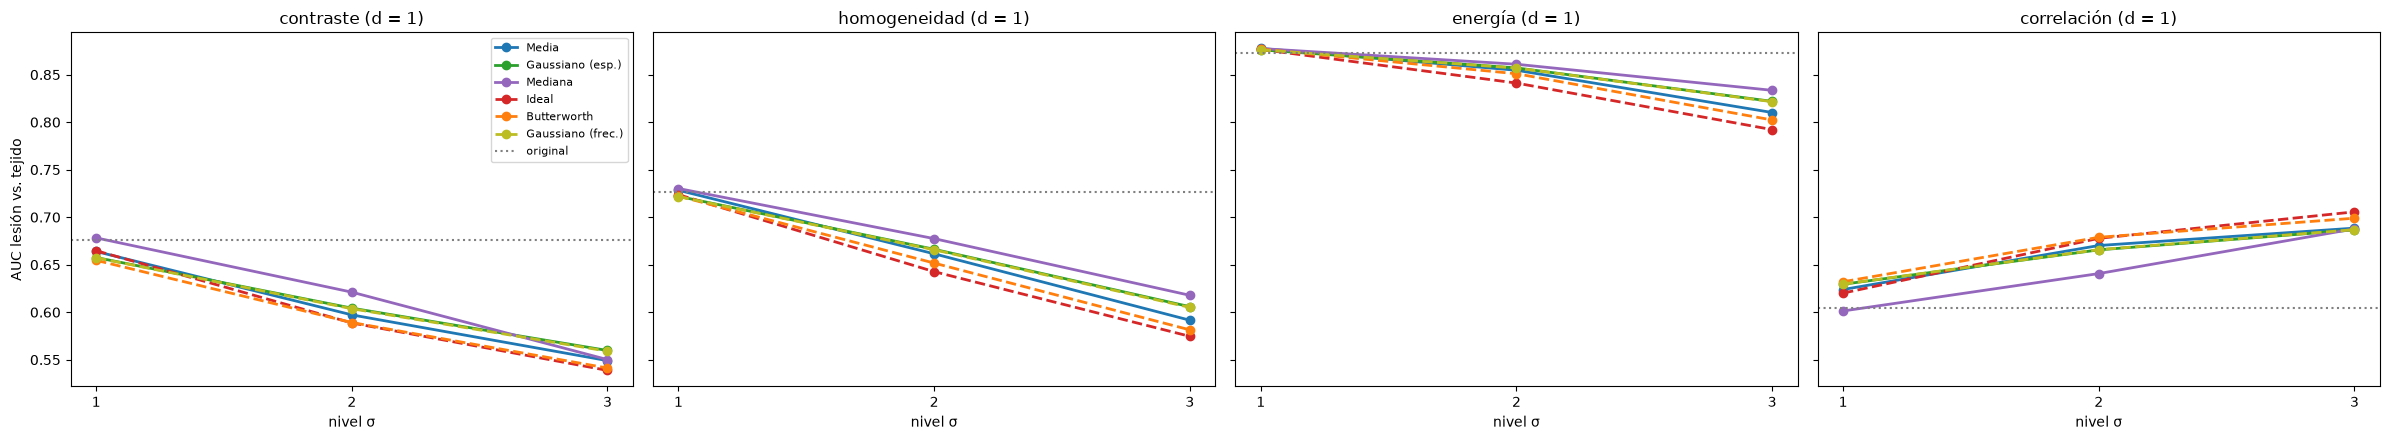

In [19]:
fig, axes = plt.subplots(1, 4, figsize=(24, 4.5), sharey=True)
original = separabilidad.loc[0].iloc[0]
for ax, p in zip(axes, props):
    for filtro in filtros:
        valores = [separabilidad.loc[(s, NOMBRES[filtro]), f"{nombres_props[p]} d1"] for s in dominios.SIGMAS]
        estilo = "--" if dominios.FILTROS[filtro] == "frecuencial" else "-"
        ax.plot(dominios.SIGMAS, valores, estilo + "o", color=COLORES[filtro], label=NOMBRES[filtro], linewidth=2)
    ax.axhline(original[f"{nombres_props[p]} d1"], color="gray", linestyle=":", label="original")
    ax.set_title(f"{nombres_props[p]} (d = 1)")
    ax.set_xlabel("nivel σ")
    ax.set_xticks(dominios.SIGMAS)
axes[0].set_ylabel("AUC lesión vs. tejido")
axes[0].legend(fontsize=8)
plt.tight_layout()
plt.show()

**Qué vemos:**
- En la **original**, la propiedad que mejor separa la lesión del tejido es la **energía** (AUC 0,87), seguida por la homogeneidad (0,73), el contraste (0,68) y la correlación (0,60).
- Con **σ = 1** la separabilidad queda **igual** que en la original con todos los filtros.
- Con **σ = 2 y 3**, el **contraste, la homogeneidad y la energía pierden separabilidad con todos los filtros**. El contraste, por ejemplo, baja de 0,68 a ~0,60 (σ = 2) y ~0,55 (σ = 3), casi azar. En general, la **mediana es la que menos pierde** y el **ideal el que más**.
- La **correlación** es la excepción: **sube** (de 0,60 a ~0,64–0,71). Al sacar el grano queda la estructura de escala mayor: el interior de la lesión es más uniforme que el tejido de capas que la rodea, y eso hace que un píxel sea más predecible a partir de su vecino. Pero no compensa: sigue bastante por debajo de la energía de la imagen sin filtrar.

**Conclusión: el *speckle* también es textura.** El grano que los filtros sacan lleva parte de la información que distingue la lesión del tejido. Filtrar mejora los bordes, pero **empeora la textura**: no hay un filtro que mejore las dos cosas a la vez.

### 5.4 ¿Cambia algo entre benignas y malignas?

En la Parte 0 vimos que las malignas tienen **menos contraste** con el tejido que las rodea. ¿El filtrado afecta igual a las dos clases? Contraste de borde por clase, en σ = 2:

In [20]:
por_clase = metricas[metricas["sigma"].isin([0, 2])].groupby(["filtro", "clase"], sort=False)["contraste_borde"].median().unstack()
por_clase.index = [NOMBRES.get(f, "Original") for f in por_clase.index]
por_clase["mejora benignas"] = por_clase["benign"] / por_clase.loc["Original", "benign"]
por_clase["mejora malignas"] = por_clase["malignant"] / por_clase.loc["Original", "malignant"]
por_clase.round(2)

clase,benign,malignant,mejora benignas,mejora malignas
Original,1.40,1.15,1.00,1.00
Media,1.72,1.32,1.22,1.15
Gaussiano (esp.),1.69,1.32,1.21,1.15
Mediana,1.76,1.34,1.26,1.17
Ideal,1.62,1.27,1.16,1.11
Butterworth,1.75,1.35,1.25,1.18
Gaussiano (frec.),1.69,1.33,1.21,1.15


**Qué vemos:**
- En la original, el borde de las **malignas** resalta menos que el de las benignas (contraste de borde 1,15 contra 1,40), como vimos en la Parte 0.
- El filtrado mejora las dos clases, pero **menos a las malignas**: con la mediana, +17 % en malignas contra +26 % en benignas.

El borde difuso de las malignas **es real** (es una característica de la lesión), no es ruido. Ningún filtro lo puede recuperar, así que las malignas van a seguir siendo **más difíciles de segmentar** en la Parte 5.

### 5.5 PSNR y SSIM

La guía de la materia propone **PSNR** (el error cuadrático medio en escala logarítmica, como en la Parte 1) y **SSIM** (índice de similitud estructural: compara brillo, contraste y estructura en ventanas locales; vale 1 si las imágenes son iguales) para medir la calidad de una imagen procesada.

**Ojo con la interpretación.** Las dos métricas comparan contra una imagen de referencia, que debería ser la imagen **sin ruido**. Acá no la tenemos: la única referencia es la imagen original, **con** *speckle*. Entonces PSNR y SSIM miden **cuánto cambió** la imagen, no cuánto mejoró: un filtro que no hace nada tendría PSNR infinito y SSIM = 1.

In [21]:
tabla_calidad = filtradas.groupby(["sigma", "nombre"], sort=False)[["psnr", "ssim"]].median().unstack(0).round(2)
tabla_calidad

psnr                ssim            
sigma                  1      2      3     1     2     3
nombre                                                  
Media              38.26  29.85  26.60  0.96  0.78  0.64
Gaussiano (esp.)   37.36  30.97  28.00  0.96  0.83  0.72
Mediana            40.42  31.50  27.96  0.97  0.82  0.69
Ideal              34.96  28.66  26.04  0.91  0.71  0.61
Butterworth        36.35  29.98  27.10  0.94  0.79  0.68
Gaussiano (frec.)  37.35  30.96  27.98  0.96  0.83  0.72

**Qué vemos:**
- Con σ = 1 la **mediana** es la que menos cambia la imagen (PSNR 40,4 dB, SSIM 0,97). Con σ = 2 y 3 los **gaussianos** son los que más conservan la estructura (SSIM 0,83 y 0,72).
- El **ideal** es el que **más cambia** la imagen (PSNR y SSIM más bajos en los tres niveles), aunque en la sección 5.1 vimos que es el que **menos suaviza**. Lo que cambia no es ruido que se fue: es el *ringing* que agrega.
- Como no tenemos una imagen sin ruido, un PSNR alto no quiere decir "mejor imagen" sino "imagen menos cambiada". **No usamos PSNR ni SSIM para elegir el filtro**: para eso están las métricas de las secciones 5.1 a 5.3, que miden lo que nos importa (ruido, borde y textura).

## 6. Conclusiones

Comparamos 6 filtros pasabajos (3 espaciales y 3 frecuenciales) con 3 niveles de suavizado emparejados, sobre las 647 ecografías con lesión de BUSI, ya sin las marcas del ecógrafo.

| Pregunta | Respuesta | Evidencia |
|---|---|---|
| ¿Dónde está la información de la imagen? | En la **fase** (la ubicación de los bordes); los pasabajos solo cambian la magnitud | Reconstrucción con magnitud o fase (sección 1.1) |
| ¿Espacial o frecuencial? | Para filtros **lineales**, el dominio no importa: el gaussiano da lo mismo en los dos. Importa la **forma** de $H$ | Control del gaussiano (sección 2), métricas (5.1) y PSD (5.2) |
| ¿Qué filtro lineal funciona mejor? | **Gaussiano** y **Butterworth**, muy parecidos. La **media** deja pasar frecuencias altas por sus lóbulos | Secciones 2, 5.1 y 5.2 |
| ¿Y el ideal? | El **peor**: suaviza menos y agrega **ringing** (fenómeno de Gibbs), que se ve como ondas y textura artificial | Perfil (3.2), Wilcoxon: pierde en el 81–100 % de las imágenes (5.1) |
| ¿Cuál preserva mejor el borde? | La **mediana** (no lineal, solo existe en el dominio espacial): con un suavizado parecido, contraste de borde 1,75 contra 1,61–1,64 (σ = 3); mejor que el gaussiano en el 73 % de las imágenes (σ = 2) | Sección 5.1 |
| ¿Por qué la mediana? | Atenúa las frecuencias medias pero **conserva las altas**: aplana zonas y deja bordes netos. Ningún pasabajos lineal puede hacer eso | PSD (5.2) |
| ¿Cuánto ruido sacan? | **Poco**: ENL ×2 como máximo. El *speckle* tiene grano grande y comparte frecuencias con la anatomía (98 % de la potencia por debajo de 0,05 ciclos/píxel) | Secciones 5.1 y 5.2 |
| ¿Qué le pasa a la textura? | Con σ ≥ 2, **todos los filtros reducen la diferencia de textura entre lesión y tejido** (contraste: AUC de 0,68 a 0,55; energía: de 0,87 a 0,79–0,83). Con σ = 1 queda igual | Sección 5.3 |
| ¿Benignas y malignas? | El borde de las malignas resalta menos y el filtro lo mejora menos: es un borde difuso real, no ruido | Sección 5.4 |

**El compromiso central:** filtrar mejora los **bordes** (hacen más contraste con el *speckle*) pero empeora la **textura** (lesión y tejido se parecen más). El *speckle* es ruido para la segmentación, pero es **información** para la textura.

**Filtro elegido para las partes siguientes.** Por ese compromiso no hay un único filtro para todo:
- **Mapas de textura** (GLCM, varianza local, coeficiente de variación, Parte 4): sobre la imagen limpia **sin filtrar**. Filtrar con σ ≥ 2 borra justamente la diferencia de textura que esos mapas buscan medir. σ = 1 no la cambia, pero tampoco aporta.
- **Lo que depende de la intensidad y los bordes** (media local y gradiente en la Parte 4; crecimiento de regiones y Chan-Vese en la Parte 5): **mediana 7 × 7** (nivel σ = 2). Es la que más resalta el borde sin agregar *ringing*, y el efecto "acuarela" todavía es moderado. La mediana 11 × 11 (σ = 3) resalta todavía más el borde pero deforma más la imagen; se puede probar en la Parte 5 si la segmentación lo necesita.
- **No usar el pasabajos ideal.**

**Limitaciones:**
1. Las **máscaras manuales** no siguen el borde con precisión de un píxel. Por eso medimos en una banda de 3 px, pero el gradiente "del borde" mezcla algo de tejido.
2. Los **parches para el ENL** están lejos de la lesión pero no siempre son homogéneos (algunos tienen fibras, como en la Parte 2), así que el ENL mide *speckle* más algo de estructura.
3. Los parámetros están en **píxeles**: no conocemos los mm por píxel de cada imagen, así que el mismo filtro puede abarcar distinta cantidad de tejido en imágenes distintas.
4. Quedan **marcas no detectadas** por la Parte 1 (*calipers* sobre tejido claro, visibles en las figuras), que aportan gradiente en algunas imágenes.
5. Solo comparamos los filtros vistos en clase. Los filtros diseñados para el *speckle* (Lee, Frost, difusión anisotrópica) quedan fuera del alcance de este trabajo.